# Assignment 09, Problem 1 — Hussein Jawad
**E89 Deep Learning · Speech analysis: the Fast Fourier Transform** (based on Lecture 9 and the class notebooks
`scipy_fft.ipynb` and `lec09_speech_analysis.ipynb`)

The notebook runs on Google Colab (**Runtime → Run all**). It only needs `numpy`, `scipy` and `matplotlib`, which Colab
already has, and it reads no data files.

---

# Problem 1: The FFT of $f(x) = 1/(a^2x^4 + b^2)$
Starting with the code in `scipy_fft.ipynb` or `lec09_speech_analysis.ipynb`, determine and plot the **real**, **imaginary**
and **absolute** value of $F(k)$, the FFT of

$$f(x) = \frac{1}{a^2x^4 + b^2}, \qquad a = b = 2 .$$

Describe and plot the changes in $F(k)$ if you change $a$ to 1, and separately, if you keep $a = 1$ but replace $x$ with
$x - 2$. Plot the three versions of $F(k)$ one below the other to emphasize the differences.

## Approach

### Goal
Compute the Fourier transform $F(k)$ of $f(x)$ numerically with the FFT, plot its real part, imaginary part and absolute
value, and explain how $F(k)$ changes when $a$ changes and when the function is shifted. The Fourier transform tells us
how much of each frequency $k$ a function contains (Appendix A.3):

$$F(k) = \int_{-\infty}^{\infty} f(x)\,e^{-2\pi i k x}\,dx .$$

### The three functions

| Version | $a$ | $b$ | Function | What changes compared with version 1 |
|---|---|---|---|---|
| 1 | 2 | 2 | $\dfrac{1}{4x^4 + 4}$ | the original: a bump centered at $x = 0$ with peak $1/b^2 = 0.25$ |
| 2 | 1 | 2 | $\dfrac{1}{x^4 + 4}$ | same peak, but $\sqrt{2}$ times **wider** |
| 3 | 1 | 2 | $\dfrac{1}{(x-2)^4 + 4}$ | same shape as version 2, **moved 2 units to the right** |

### Steps

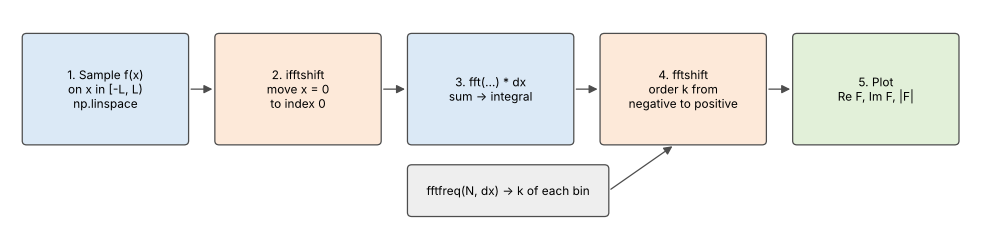

1. **Sample** $f(x)$ at $N = 8192$ evenly spaced points on $[-40, 40)$, so the spacing is $dx \approx 0.0098$.
   The window is wide enough that $f$ is practically zero at its edges (Appendix A.4).
2. **`ifftshift`** puts the sample at $x = 0$ first, because the FFT measures positions from the first sample (Appendix A.4).
3. **`fft(...) * dx`**: the FFT computes a sum over the samples; multiplying by $dx$ turns that sum into an approximation of
   the integral above (Appendix A.4).
4. **`fftfreq(N, dx)`** gives the frequency $k$ of every output value, and **`fftshift`** orders them from negative to
   positive $k$ for plotting.
5. **Plot** `np.real`, `np.imag` and `np.abs` of $F(k)$ for each version, and **check** the results against exact values:
   the FFT curves must match the exact Fourier transform of $f(x)$ (known in closed form), and the shifted transform must
   equal the unshifted one times $e^{-4\pi i k}$.
6. **Plot the three versions one below the other** with identical axes.

### What the theory predicts (explained in the Appendix)
* **Version 1:** $f$ is real and symmetric about $x = 0$ (even), so $F(k)$ is **real** and $\text{Im}\,F(k) = 0$ (A.5).
* **Version 2:** $f$ is $\sqrt{2}$ times wider, so $F(k)$ is $\sqrt{2}$ times **narrower** and $\sqrt{2}$ times **taller**
  (Similarity Theorem, A.6).
* **Version 3:** shifting $f$ does not change $|F(k)|$; it only multiplies $F(k)$ by $e^{-4\pi i k}$, so the real and
  imaginary parts **oscillate** (Time Shifting Property, A.7).

### Code
The code follows `scipy_fft.ipynb`: `np.linspace(..., endpoint=False)` for the samples, `fft()` and `fftfreq()` for the
transform, and `np.abs()` for the magnitude. The additions are:
* a function `f(x, a, b, shift)` that gives all three versions,
* `ifftshift` / `fftshift` and the factor `dx`, because here we want the continuous Fourier transform of a function
  centered at $x = 0$ (in `scipy_fft.ipynb` only the location of the peaks mattered),
* checks against exact values, and plots of `np.real` and `np.imag` as well as `np.abs`.

## Solution

### Step 1: Imports

In [1]:
import numpy as np                                   # numerical arrays and math functions
from matplotlib import pyplot as plt                 # plotting
from scipy.fft import fft, fftfreq, fftshift, ifftshift  # FFT, bin frequencies, and helpers to re-center arrays

### Step 2: Sampling grid
The window length `2L` and the number of samples `N` play the roles of `DURATION` and `SAMPLE_RATE * DURATION` in
`scipy_fft.ipynb`. The function decays like $1/x^4$, so a window of $[-40, 40)$ is wide enough for $f$ (and its shifted
version) to be practically zero at the edges. The spacing between neighboring values of $k$ is $1/(2L) = 0.0125$,
which makes the curves smooth.

In [2]:
L = 40.0                                       # half-width of the x window: samples cover [-L, L)
N = 8192                                       # number of samples (a power of 2 keeps the FFT fast)
x = np.linspace(-L, L, N, endpoint=False)      # evenly spaced grid; endpoint=False because the FFT assumes periodicity
dx = x[1] - x[0]                               # sample spacing (the analogue of 1/SAMPLE_RATE)
print("dx =", dx)                              # show the spacing between samples
print("largest k the FFT can resolve (Nyquist) =", 1 / (2 * dx))  # Nyquist frequency = half the sampling rate

dx = 0.009765625
largest k the FFT can resolve (Nyquist) = 51.2


### Step 3: Define $f(x)$ and the FFT helper
`f()` takes an optional `shift` so the same function also gives $f(x - 2)$.
`fourier()` wraps the `fft` / `fftfreq` calls from `scipy_fft.ipynb` (see the pipeline in the Approach).

In [3]:
def f(x, a, b, shift=0.0):                       # f(x - shift); shift = 0 gives the original f(x)
    return 1.0 / (a**2 * (x - shift)**4 + b**2)   # 1 / (a^2 (x - shift)^4 + b^2), evaluated on the whole x array

def fourier(y):                        # approximate continuous Fourier transform of samples y taken on grid x
    yf = fft(ifftshift(y)) * dx        # ifftshift puts x = 0 at index 0; * dx turns the FFT sum into an integral
    k = fftfreq(N, dx)                 # frequency k (cycles per unit of x) at the center of each FFT bin
    return fftshift(k), fftshift(yf)   # reorder both arrays from negative k to positive k for plotting

### Step 4: Plot the three versions of $f(x)$

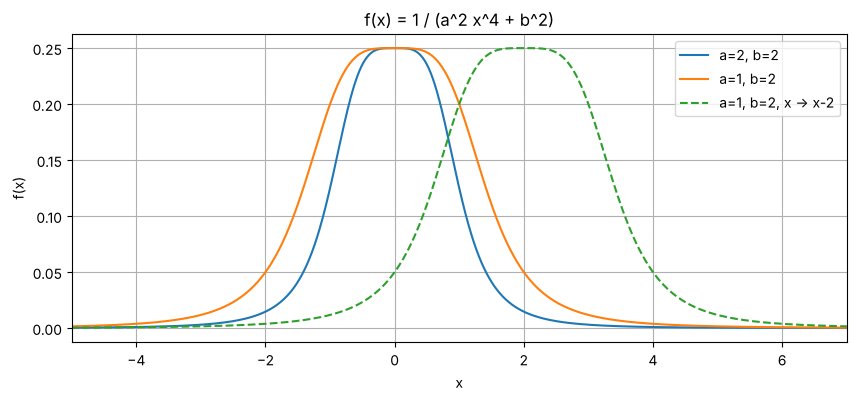

In [4]:
y1 = f(x, a=2, b=2)                    # version 1: a = b = 2
y2 = f(x, a=1, b=2)                    # version 2: a changed to 1
y3 = f(x, a=1, b=2, shift=2)           # version 3: a = 1 and x replaced by x - 2

plt.figure(figsize=(10, 4))                                # one wide figure for all three curves
plt.plot(x, y1, label="a=2, b=2")                          # original function
plt.plot(x, y2, label="a=1, b=2")                          # wider function
plt.plot(x, y3, "--", label="a=1, b=2, x -> x-2")          # same as y2 but shifted right by 2
plt.xlim(-5, 7)                                            # zoom in where the functions are non-negligible
plt.xlabel("x")                                            # horizontal axis label
plt.ylabel("f(x)")                                         # vertical axis label
plt.title("f(x) = 1 / (a^2 x^4 + b^2)")                    # plot title
plt.legend()                                               # show which curve is which
plt.grid(True)                                             # light grid for easier reading
plt.show()                                                 # render the figure

### Step 5: FFT of $f(x)$ for $a = b = 2$: real, imaginary and absolute value
The imaginary part is drawn on about the same scale as the real part. It is zero apart from round-off errors of about
$10^{-17}$ (printed below the plot); if matplotlib were allowed to autoscale that panel, it would magnify this noise into
meaningless spikes.

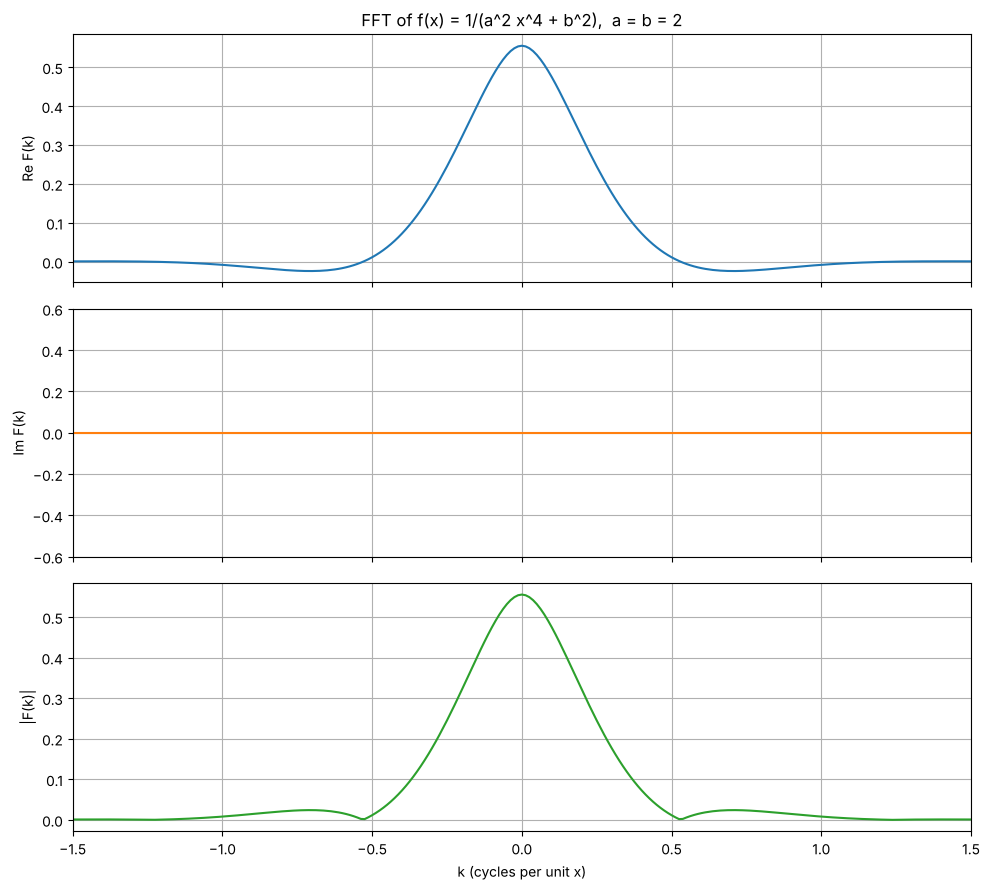

max |Im F(k)| = 6.288372600415926e-17


In [5]:
k, F1 = fourier(y1)                    # k axis and complex F(k) for a = b = 2

KMAX = 1.5                             # F(k) is negligible beyond |k| ~ 1.5, so zoom in there

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)   # three panels stacked vertically, shared k axis
ax[0].plot(k, np.real(F1), color="C0")                       # real part of F(k)
ax[0].set_ylabel("Re F(k)")                                  # label for the real-part panel
ax[0].set_title("FFT of f(x) = 1/(a^2 x^4 + b^2),  a = b = 2")  # figure title on the top panel
ax[1].plot(k, np.imag(F1), color="C1")                       # imaginary part of F(k)
ax[1].set_ylabel("Im F(k)")                                  # label for the imaginary-part panel
ax[1].set_ylim(-0.6, 0.6)                                    # about the range of Re F(k); autoscale would magnify 1e-17 round-off noise
ax[2].plot(k, np.abs(F1), color="C2")                        # magnitude |F(k)| = sqrt(Re^2 + Im^2)
ax[2].set_ylabel("|F(k)|")                                   # label for the magnitude panel
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label on the bottom panel
for axis in ax:                                              # apply common settings to every panel
    axis.set_xlim(-KMAX, KMAX)                               # same zoom on all panels
    axis.grid(True)                                          # light grid
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

print("max |Im F(k)| =", np.max(np.abs(np.imag(F1))))        # imaginary part should be ~0 (round-off only)

### Step 6: Check against the exact Fourier transform
For this function the integral can be done exactly (by contour integration, or from a table of Fourier transforms).
For $g(u) = 1/(u^4 + 1)$:

$$G(k) = \frac{\pi}{\sqrt{2}}\,e^{-\sqrt{2}\pi|k|}\left[\cos\!\left(\sqrt{2}\pi k\right) + \sin\!\left(\sqrt{2}\pi|k|\right)\right].$$

Our function is a rescaled copy of $g$: $f(x) = \frac{1}{b^2}\,g(x/s)$ with width $s = (b/a)^{1/2}$, so by the Similarity
Theorem (Appendix A.6) $F(k) = \frac{s}{b^2}\,G(s\,k)$. Three things follow:
* at $k = 0$: $F(0) = \frac{\pi}{\sqrt{2}}\,a^{-1/2}\,b^{-3/2}$, which is the area under $f(x)$ (A.3);
* $F(k)$ is a decaying exponential times $(\cos + \sin)$, i.e. a **damped oscillation**: this is why $F(k)$ dips below zero
  after its main peak;
* the first zero is where $\cos\theta + \sin\theta = 0$, i.e. $\theta = 3\pi/4$, which gives $k_0 = \frac{3}{4\sqrt{2}}\sqrt{a/b}$.

The code compares the whole FFT curve with this formula, not only $F(0)$.

In [6]:
def F_exact(k, a, b):                                        # exact Fourier transform of 1/(a^2 x^4 + b^2)
    s = np.sqrt(b / a)                                       # width s: f(x) = (1/b^2) g(x/s) with g(u) = 1/(u^4 + 1)
    t = np.sqrt(2) * np.pi * s * np.abs(k)                   # sqrt(2) pi |s k|, the argument used in G above
    return s / b**2 * np.pi / np.sqrt(2) * np.exp(-t) * (np.cos(t) + np.sin(t))  # (s/b^2) G(s k)

i0 = np.argmin(np.abs(k))                                    # index of the bin at k = 0
print("a=2, b=2:  FFT F(0) =", F1[i0].real, "  exact F(0) =", F_exact(0, 2, 2))  # F(0) = area under f(x)
print("largest difference from the exact F(k), all k:", np.max(np.abs(F1 - F_exact(k, 2, 2))))  # whole curve

a=2, b=2:  FFT F(0) = 0.5553577631034099   exact F(0) = 0.5553603672697958
largest difference from the exact F(k), all k: 2.604166385866691e-06


### Step 7: Change $a$ to 1 (keep $b = 2$)
The dashed gray curves repeat version 1 for comparison. The code compares the FFT with the exact transform again, and
finds the first zero of $F(k)$ for both versions to measure how much narrower the transform became.

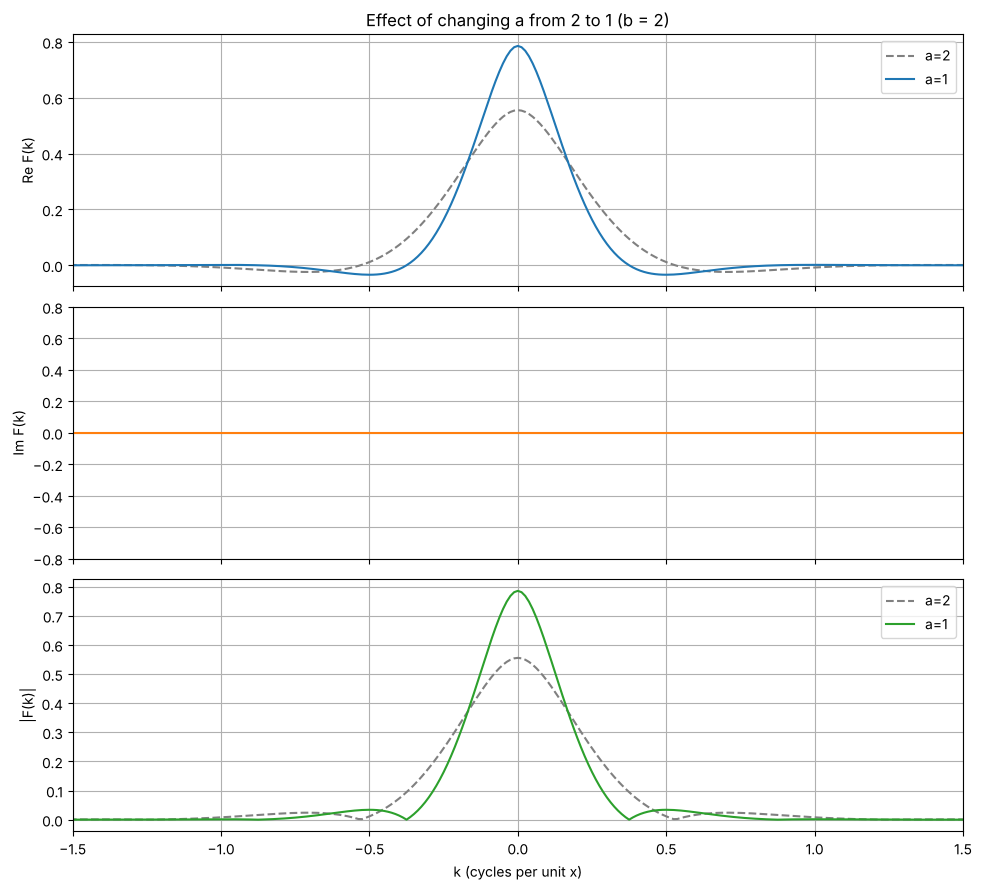

a=1, b=2:  FFT F(0) = 0.7853877467371362   exact F(0) = 0.7853981633974483
largest difference from the exact F(k), all k: 1.0416660312095871e-05
max |Im F(k)| = 8.409343100340694e-17
first zero of F(k):  a=2 -> 0.5305007613443261   a=1 -> 0.3749999803772963   ratio = 1.4146687709438726
exact first zeros:          a=2 -> 0.5303300858899106   a=1 -> 0.375


In [7]:
k, F2 = fourier(y2)                                          # complex F(k) for a = 1, b = 2

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)   # three stacked panels, as before
ax[0].plot(k, np.real(F1), "--", color="gray", label="a=2")  # reference: real part for a = 2
ax[0].plot(k, np.real(F2), color="C0", label="a=1")          # real part for a = 1
ax[0].set_ylabel("Re F(k)")                                  # panel label
ax[0].set_title("Effect of changing a from 2 to 1 (b = 2)")  # figure title
ax[0].legend()                                               # identify the two curves
ax[1].plot(k, np.imag(F2), color="C1")                       # imaginary part for a = 1
ax[1].set_ylabel("Im F(k)")                                  # panel label
ax[1].set_ylim(-0.8, 0.8)                                    # about the range of Re F(k), so the ~0 imaginary part shows as a flat line
ax[2].plot(k, np.abs(F1), "--", color="gray", label="a=2")   # reference: magnitude for a = 2
ax[2].plot(k, np.abs(F2), color="C2", label="a=1")           # magnitude for a = 1
ax[2].set_ylabel("|F(k)|")                                   # panel label
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label
ax[2].legend()                                               # identify the two curves
for axis in ax:                                              # common settings for every panel
    axis.set_xlim(-KMAX, KMAX)                               # same zoom as before
    axis.grid(True)                                          # light grid
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

print("a=1, b=2:  FFT F(0) =", F2[i0].real, "  exact F(0) =", F_exact(0, 1, 2))  # area check for a = 1
print("largest difference from the exact F(k), all k:", np.max(np.abs(F2 - F_exact(k, 1, 2))))  # whole curve
print("max |Im F(k)| =", np.max(np.abs(np.imag(F2))))        # still ~0: f is still real and even

def first_zero(F):                                           # smallest k > 0 where Re F(k) changes sign
    kp, Fp = k[k > 0], np.real(F[k > 0])                     # keep only positive frequencies
    i = np.where(np.diff(np.sign(Fp)) != 0)[0][0]            # last bin before the first sign flip
    return kp[i] - Fp[i] * (kp[i+1] - kp[i]) / (Fp[i+1] - Fp[i])  # linear interpolation between the two bins

z1, z2 = first_zero(F1), first_zero(F2)                      # first zeros of F(k) for a = 2 and a = 1
print("first zero of F(k):  a=2 ->", z1, "  a=1 ->", z2, "  ratio =", z1 / z2)  # ratio should be ~sqrt(2) = 1.414
k0 = lambda a, b: 3 / (4 * np.sqrt(2)) * np.sqrt(a / b)    # exact first zero from Step 6: k0 = 3/(4 sqrt 2) * sqrt(a/b)
print("exact first zeros:          a=2 ->", k0(2, 2), "  a=1 ->", k0(1, 2))  # compare with the FFT values above

### Step 8: Keep $a = 1$ and replace $x$ with $x - 2$
The bottom panel compares $|F(k)|$ with the unshifted version 2. The code then checks the Time Shifting Property
$F_3(k) = e^{-2\pi i k \cdot 2}\,F_2(k)$ numerically.

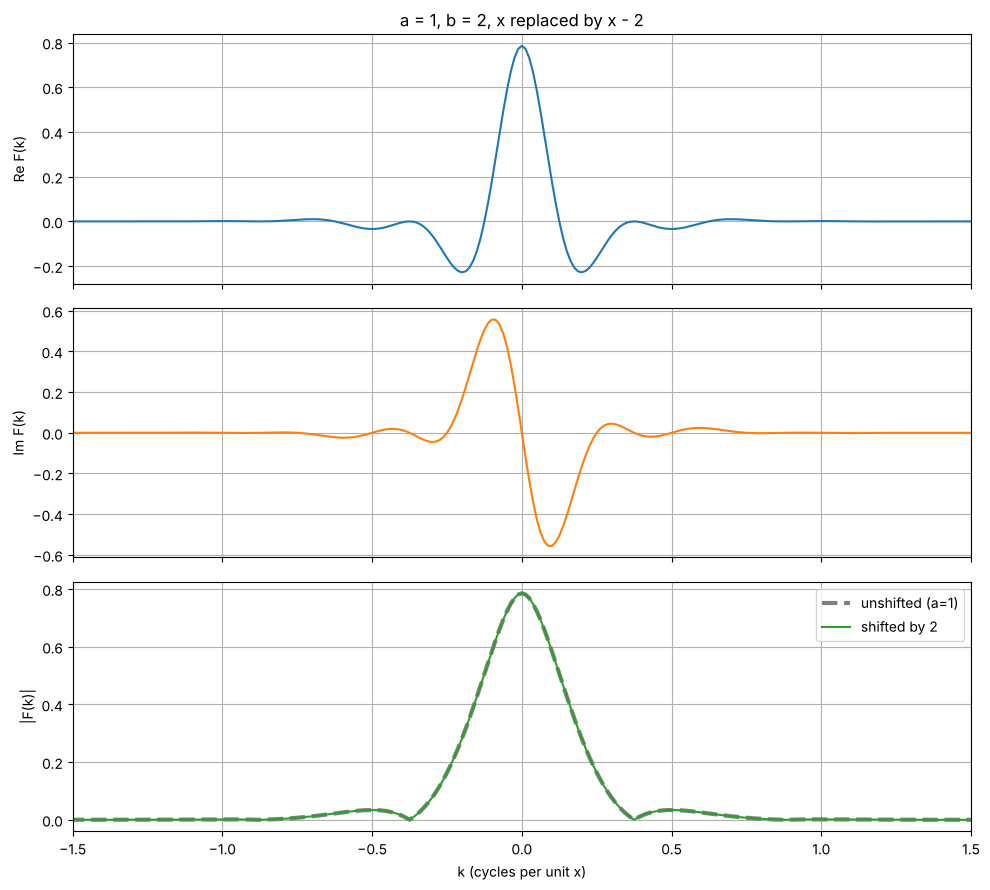

max | |F3| - |F2| | = 1.5800320496417442e-07
max | F3 - F2*exp(-4*pi*i*k) | = 1.5800320496417442e-07


In [8]:
k, F3 = fourier(y3)                                          # complex F(k) for a = 1, b = 2, shifted by 2

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)   # three stacked panels
ax[0].plot(k, np.real(F3), color="C0")                       # real part: now oscillates
ax[0].set_ylabel("Re F(k)")                                  # panel label
ax[0].set_title("a = 1, b = 2, x replaced by x - 2")         # figure title
ax[1].plot(k, np.imag(F3), color="C1")                       # imaginary part: no longer zero
ax[1].set_ylabel("Im F(k)")                                  # panel label
ax[2].plot(k, np.abs(F2), "--", color="gray", lw=3, label="unshifted (a=1)")  # reference magnitude
ax[2].plot(k, np.abs(F3), color="C2", label="shifted by 2")  # magnitude of the shifted version
ax[2].set_ylabel("|F(k)|")                                   # panel label
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label
ax[2].legend()                                               # identify the two curves
for axis in ax:                                              # common settings
    axis.set_xlim(-KMAX, KMAX)                               # same zoom as before
    axis.grid(True)                                          # light grid
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

print("max | |F3| - |F2| | =", np.max(np.abs(np.abs(F3) - np.abs(F2))))   # magnitudes should be identical
print("max | F3 - F2*exp(-4*pi*i*k) | =",                    # label for the next value
      np.max(np.abs(F3 - F2 * np.exp(-2j * np.pi * k * 2))))  # check the Time Shifting Property: F3 = F2 * e^{-2 pi i k 2}

### Step 9: The three versions of $F(k)$ one below the other
Each panel shows Re $F(k)$, Im $F(k)$ and $|F(k)|$ with identical axes so the differences are easy to see.

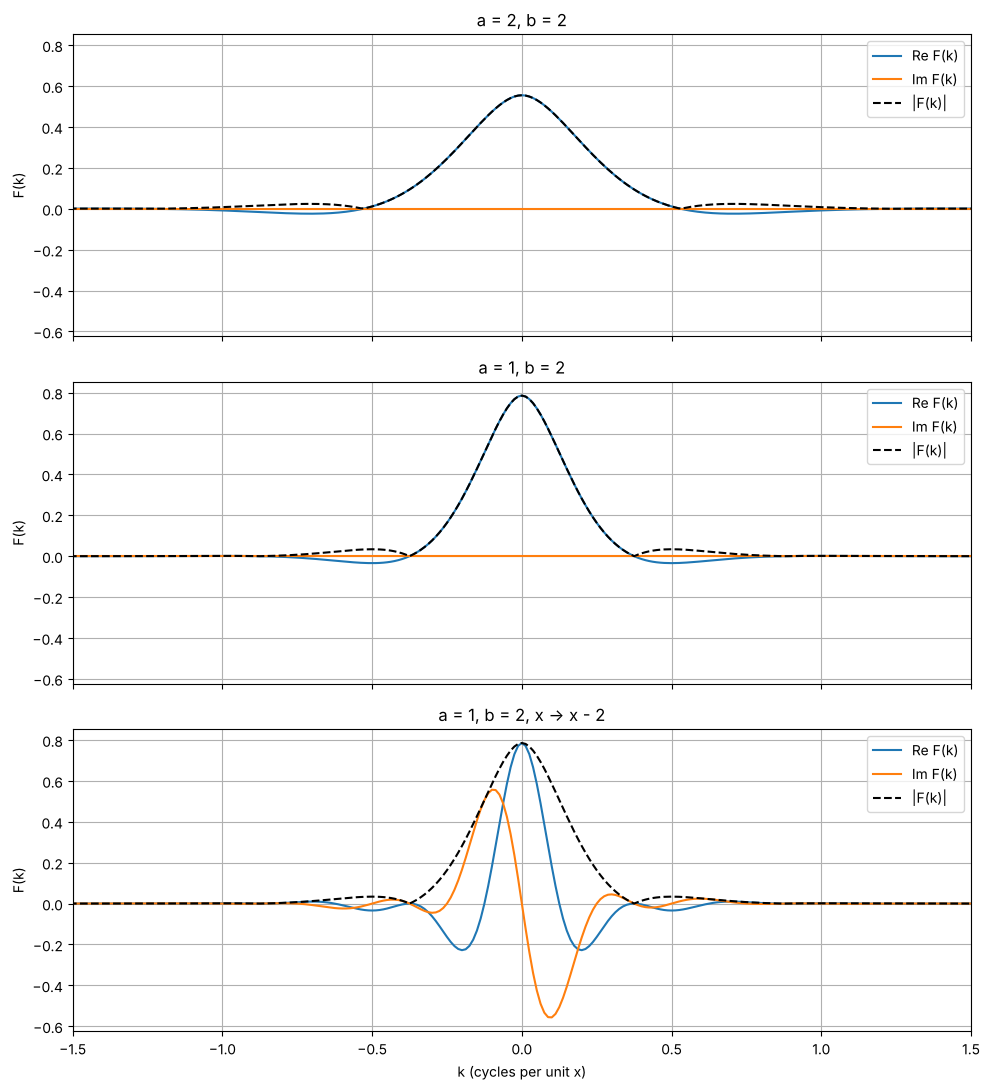

In [9]:
versions = [(F1, "a = 2, b = 2"),                            # version 1: original
            (F2, "a = 1, b = 2"),                            # version 2: a changed to 1
            (F3, "a = 1, b = 2, x -> x - 2")]                # version 3: a = 1 and shifted by 2

fig, ax = plt.subplots(3, 1, figsize=(10, 11), sharex=True, sharey=True)  # stacked panels with identical axes
for i, (F, name) in enumerate(versions):                     # one panel per version
    ax[i].plot(k, np.real(F), label="Re F(k)")               # real part
    ax[i].plot(k, np.imag(F), label="Im F(k)")               # imaginary part
    ax[i].plot(k, np.abs(F), "k--", label="|F(k)|")          # magnitude (dashed black envelope)
    ax[i].set_title(name)                                    # which version this panel shows
    ax[i].set_ylabel("F(k)")                                 # vertical axis label
    ax[i].set_xlim(-KMAX, KMAX)                              # same zoom on every panel
    ax[i].grid(True)                                         # light grid
    ax[i].legend(loc="upper right")                          # legend in each panel
ax[2].set_xlabel("k (cycles per unit x)")                    # shared x label on the bottom panel
plt.tight_layout()                                           # avoid overlapping labels
plt.show()                                                   # render the figure

## Results and discussion
The numbers are rounded; the exact values are printed in the outputs of Steps 5–8.

### Results

| Version | $F(0)$ from the FFT | exact $F(0)$ | largest difference from the exact $F(k)$ | largest $\lvert\text{Im}\,F(k)\rvert$ | first zero of $F(k)$ (exact) | $\lvert F(k)\rvert$ |
|---|---|---|---|---|---|---|
| 1: $a=2,\ b=2$ | 0.55536 | 0.55536 | $2.6\cdot10^{-6}$ | $6\cdot10^{-17}$ (zero) | 0.5305 (0.5303) | one peak, small side lobes |
| 2: $a=1,\ b=2$ | 0.78539 | 0.78540 ($=\pi/4$) | $1.0\cdot10^{-5}$ | $8\cdot10^{-17}$ (zero) | 0.3750 (0.3750) | $\sqrt{2}$ times taller and narrower |
| 3: $a=1,\ b=2,\ x\to x-2$ | 0.78539 | 0.78540 | – | 0.56 (not zero) | – | same as version 2 (difference $1.6\cdot10^{-7}$) |

### Discussion
1. **Version 1 ($a = b = 2$).** $F(k)$ is a smooth peak at $k = 0$ that is almost zero beyond $|k| \approx 1$. It is
   **real**: the imaginary part is only round-off noise ($\sim10^{-17}$), because $f(x)$ is real and symmetric about
   $x = 0$ (A.5). So $|F(k)|$ equals $\text{Re}\,F(k)$ where $F(k) \ge 0$. Between $|k| \approx 0.53$ and about $1.2$,
   $\text{Re}\,F(k)$ dips slightly below zero (minimum about $-0.024$ near $|k| \approx 0.7$); in $|F(k)|$ this shows up as
   a small second bump. The exact transform (Step 6) explains these side lobes: $F(k)$ is a decaying exponential times
   $(\cos + \sin)$, a damped oscillation, so it crosses zero at $k \approx 0.530$ and keeps oscillating with a rapidly
   shrinking amplitude. The whole FFT curve agrees with the exact formula to $2.6\cdot10^{-6}$, which confirms the $dx$
   scaling and the centering with `ifftshift`.
2. **Changing $a$ from 2 to 1.** The peak of $f(x)$ stays at $1/b^2 = 0.25$, but $f(x)$ becomes $\sqrt{2}$ times wider,
   because its width $s = (b/a)^{1/2}$ (Step 6) grows from 1 to $\sqrt{2}$. By the **Similarity Theorem** (A.6) the
   transform does the opposite: $F(k) = \frac{s}{b^2}\,G(s\,k)$ becomes $\sqrt{2}$ times narrower and $\sqrt{2}$ times
   taller. Both effects are measured: $F(0)$ grows from 0.555 to 0.785 (ratio 1.414) and the first zero moves from
   $k \approx 0.530$ to $0.375$
   (ratio 1.415; the exact zeros 0.5303 and 0.3750 have ratio exactly $\sqrt{2}$). $F(k)$ is still real, because $f$ is
   still even.
3. **Replacing $x$ with $x - 2$.** $|F(k)|$ does **not** change (the two curves in Step 8 lie on top of each other), because
   moving a function does not change which frequencies it contains. What changes is the **phase**: by the
   **Time Shifting Property** (A.7), $F_3(k) = e^{-4\pi i k}\,F_2(k)$, so
   $\text{Re}\,F_3 = F_2(k)\cos(4\pi k)$ and $\text{Im}\,F_3 = -F_2(k)\sin(4\pi k)$. The real and imaginary parts now
   oscillate with period $\Delta k = 1/2$ inside the envelope $\pm|F(k)|$, and the imaginary part is no longer zero because
   $f(x-2)$ is not symmetric about $x = 0$. The real part is still even in $k$ and the imaginary part is odd, as for every
   real function. The numerical check agrees with the formula to $1.6\cdot10^{-7}$.
4. **Accuracy.** The small remaining differences come from cutting the slowly decaying $1/x^4$ tails off at
   $x = \pm 40$. The area of the two missing tails is about $2\int_{40}^{\infty}\frac{dx}{a^2x^4} = \frac{2}{3a^2\cdot 40^3}$,
   i.e. $2.6\cdot10^{-6}$ for $a = 2$ and $1.0\cdot10^{-5}$ for $a = 1$: exactly the differences from the exact
   transform found in Steps 6 and 7. A sampling spacing of $dx \approx 0.01$ is far finer than needed: the Nyquist
   frequency is $k = 51.2$, while $F(k)$ is negligible beyond $|k| \approx 1.5$.

### Conclusion
The FFT code from `scipy_fft.ipynb`, with `ifftshift`/`fftshift` and the factor $dx$ added, reproduces the continuous Fourier
transform of $f(x)$ accurately. The three versions illustrate two basic properties from Lecture 9:
* **changing $a$ changes the width**: a wider $f(x)$ has a narrower, taller $F(k)$ (Similarity Theorem);
* **shifting $x$ changes only the phase**: $|F(k)|$ stays the same, while the real and imaginary parts oscillate
  (Time Shifting Property).

This is also why speech features such as spectrograms and MFCCs are built from the magnitude $|F(k)|$ of each short
frame: the magnitude describes which frequencies are present, while the phase mostly records exactly where the waves sit
inside the frame.

---
# Appendix: The Fourier transform ideas behind Problem 1
This appendix explains, from the beginning, the ideas used in Problem 1. It follows Lecture 9 (Part 1, slides 15–22),
with pictures and small examples that can be checked by hand.

### Words used in this appendix

| Word | Meaning |
|---|---|
| frequency $k$ | how many cycles (ups and downs) a wave makes per unit of $x$. If $x$ is time in seconds, $k$ is in Hz |
| spectrum | the list of "how much" of each frequency a signal contains |
| complex number | a number $z = \text{Re} + i\,\text{Im}$ with a real part and an imaginary part; $i = \sqrt{-1}$ |
| magnitude $\lvert z\rvert$ | the length of $z$: $\sqrt{\text{Re}^2 + \text{Im}^2}$ (`np.abs`) |
| phase | the angle of $z$ (`np.angle`); for a wave it says where the wave is shifted to |
| even / odd function | even: $f(-x) = f(x)$ (mirror image, like $\cos$); odd: $f(-x) = -f(x)$ (like $\sin$) |
| sample, $dx$ | a value of the function at one point; $dx$ is the distance between neighboring samples |
| sampling rate | samples per unit of $x$, i.e. $1/dx$ (`SAMPLE_RATE` in `scipy_fft.ipynb`) |
| Nyquist frequency | the highest frequency the samples can represent: half the sampling rate, $1/(2\,dx)$ |
| DFT / FFT | the Discrete Fourier Transform is the sum that `fft()` computes; the FFT is a fast way to compute it |
| bin | one output value of the FFT; it belongs to one frequency $k$ given by `fftfreq` |

## A.1 Every signal is a sum of waves (Fourier series)
Lecture 9 (slide 15): any periodic function can be written as a sum of sines and cosines of different frequencies.
The picture shows a square wave built from sine waves with frequencies 1, 3, 5, … Hz:

$$\text{square}(x) = \frac{4}{\pi}\left[\sin(2\pi x) + \frac{\sin(2\pi\cdot 3x)}{3} + \frac{\sin(2\pi\cdot 5x)}{5} + \dots\right]$$

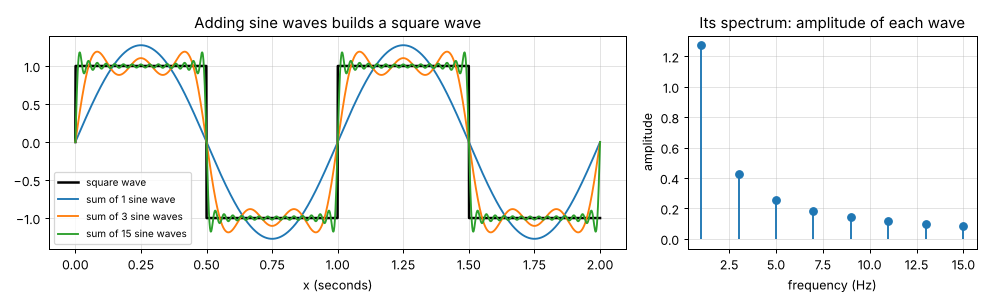

With 1 wave the result is only roughly square; with 15 waves it is close. The list of amplitudes on the right is the
**spectrum** of the square wave: it says how much of each frequency is needed. This is the same idea as the speech
spectrograms in Lecture 9, which show how much of each frequency a voice contains at each moment.

## A.2 Complex numbers and Euler's formula
Lecture 9 (slide 16) connects waves with the exponential function through **Euler's formula**:

$$e^{i\theta} = \cos\theta + i\,\sin\theta .$$

$e^{i\theta}$ is a point on a circle of radius 1: its real part is $\cos\theta$ and its imaginary part is $\sin\theta$
(left picture). As $\theta$ grows, the point goes around the circle, so $e^{i\theta}$ is a "rotating arrow" that contains
both a cosine and a sine wave.

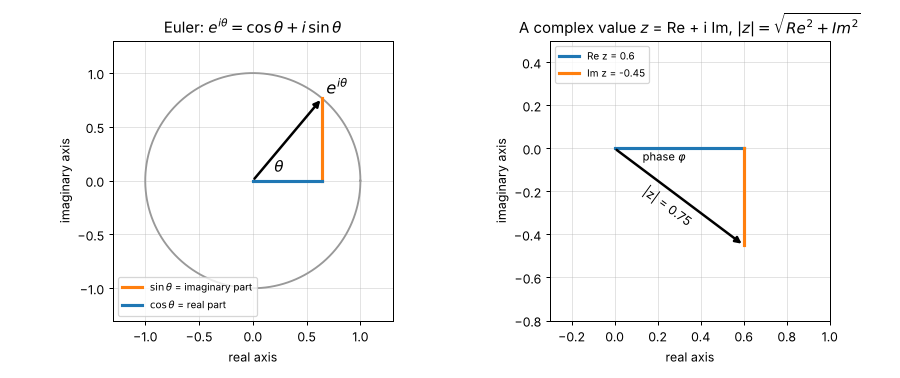

Any complex number $z$ (right picture) can be described in two ways:
* by its **real and imaginary parts** (`np.real(z)`, `np.imag(z)`): $z = 0.6 - 0.45\,i$;
* by its **magnitude and phase** (`np.abs(z)`, `np.angle(z)`): length $|z| = \sqrt{0.6^2 + 0.45^2} = 0.75$ and angle
  $\varphi \approx -37°$.

The FFT returns complex numbers. Problem 1 plots all three of `np.real`, `np.imag` and `np.abs`: the magnitude says
**how much** of a frequency is present, and the phase (hidden in the split between real and imaginary part) says **where**
the wave is positioned.

## A.3 The Fourier transform: how much of each frequency
A function that is not periodic, such as our bump $f(x)$, needs all frequencies, not just 1, 3, 5, …, so the sum of A.1
becomes an integral:

$$F(k) = \int_{-\infty}^{\infty} f(x)\,e^{-2\pi i k x}\,dx
       = \underbrace{\int f(x)\cos(2\pi k x)\,dx}_{\text{Re}\,F(k)} \; - \; i\,\underbrace{\int f(x)\sin(2\pi k x)\,dx}_{-\text{Im}\,F(k)}$$

(using Euler's formula). This is exactly the definition on Lecture 9, slide 17, and it is also the convention of
`scipy.fft`: $k$ is measured in cycles per unit of $x$ (Hz when $x$ is in seconds).

**What $F(k)$ measures.** For each $k$, multiply $f(x)$ by a wave of frequency $k$ and measure the area (blue counts as
positive, orange as negative):

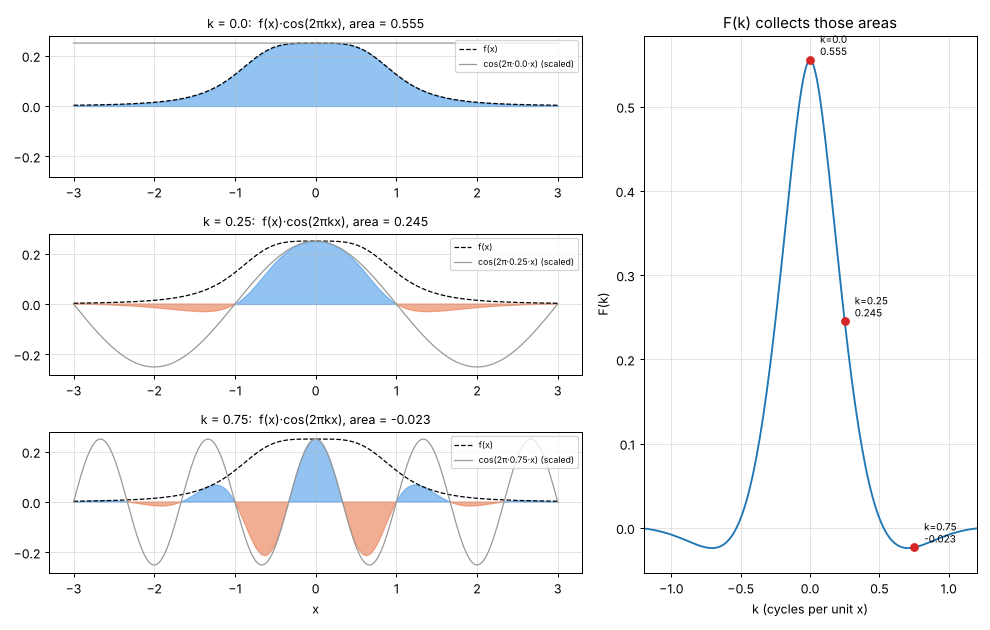

* $k = 0$: the "wave" is constant, so $F(0)$ is simply the **area under $f(x)$**, 0.555 (Step 6 of the solution).
* $k = 0.25$: the slow wave still mostly overlaps the bump with the same sign, so the area is still large (0.245).
* $k = 0.75$: the fast wave goes up and down within the bump, so positive and negative areas almost cancel ($-0.023$).

So $F(k)$ is large for frequencies that "fit" the shape of $f(x)$ and small for frequencies that do not. A smooth, wide
bump only contains slow waves, which is why $F(k)$ is concentrated near $k = 0$.

## A.4 From the integral to the FFT

### Sampling and $dx$
A computer only knows $f$ at the samples $x_n$, spaced $dx$ apart. The integral becomes a sum of thin rectangles,
each of width $dx$:

$$F(k) \approx \sum_n f(x_n)\,e^{-2\pi i k x_n}\,dx .$$

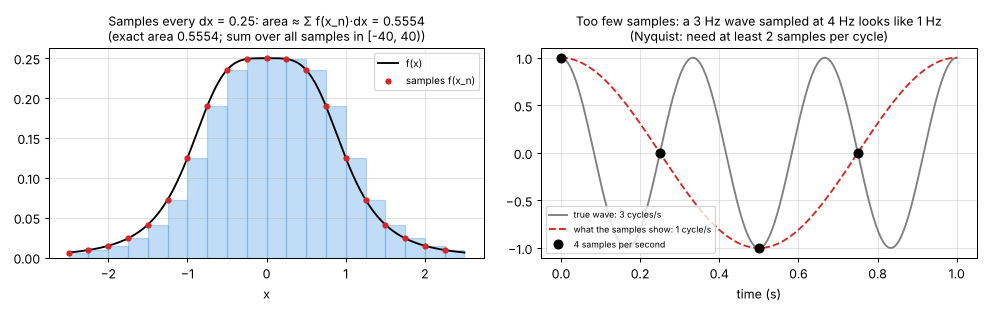

* **Left:** even with coarse samples ($dx = 0.25$) the rectangles give the area almost exactly. This is why the solution
  multiplies the FFT by `dx`: without it the result would be $1/dx \approx 102$ times too large.
* **Right:** sampling must be fine enough for the fastest wave we care about. Lecture 9 (slides 21–22): at least two
  samples per cycle are needed (strictly, a little more than two), so the highest frequency that can be represented is
  the **Nyquist frequency** $1/(2\,dx)$. A 3 Hz wave sampled only 4 times per second looks exactly like a 1 Hz wave. In Problem 1, $dx \approx 0.0098$
  gives a Nyquist frequency of 51.2, far above $|k| \approx 1.5$, where $F(k)$ is already negligible.
* The spacing between neighboring frequencies is $1/(N\,dx) = 1/(2L) = 0.0125$. A wider window (larger $L$) gives more
  finely spaced values of $k$ and smoother curves.

### What `fft()` computes
For $N$ samples $y_0, \dots, y_{N-1}$, `fft()` returns $N$ numbers (the Discrete Fourier Transform, DFT)

$$Y_m = \sum_{n=0}^{N-1} y_n\,e^{-2\pi i\,m n / N}, \qquad m = 0, 1, \dots, N-1 .$$

With $x_n = n\,dx$ (true after `ifftshift`, see below) and $k_m = m/(N\,dx)$ (this is what `fftfreq(N, dx)`
returns) the exponent equals
$-2\pi i k_m x_n$, so $Y_m\,dx$ is exactly the rectangle sum above: $F(k_m) \approx Y_m\,dx$.

**A 4-point example by hand.** Take $y = [4, 2, 0, 2]$ (for $N = 4$, $e^{-2\pi i\,m n/4}$ is one of $1, -i, -1, i$):

| $m$ | $Y_m = y_0 + y_1 e^{-2\pi i m/4} + y_2 e^{-2\pi i\,2m/4} + y_3 e^{-2\pi i\,3m/4}$ | result |
|---|---|---|
| 0 | $4 + 2 + 0 + 2$ | 8 |
| 1 | $4 + 2(-i) + 0(-1) + 2(i)$ | 4 |
| 2 | $4 + 2(-1) + 0(1) + 2(-1)$ | 0 |
| 3 | $4 + 2(i) + 0(-1) + 2(-i)$ | 4 |

All four results are real because $y_1 = y_3$: the samples are symmetric around index 0 (an "even" sequence, see A.5).
$Y_0 = 8$ is the sum of the samples, the discrete version of "$F(0)$ = area". The cell below repeats the calculation.

In [10]:
y4 = np.array([4.0, 2.0, 0.0, 2.0])                   # 4 samples; y4[1] = y4[3], so they are symmetric around index 0
n = np.arange(4)                                      # sample index n = 0, 1, 2, 3
for m in range(4):                                    # one output value m at a time
    Y = np.sum(y4 * np.exp(-2j * np.pi * m * n / 4))  # the DFT sum: each sample times the wave e^{-2 pi i m n / 4}
    print(f"m = {m}:  Y_m = {np.round(Y.real, 6) + 0.0} + {np.round(Y.imag, 6) + 0.0}i")  # rounding hides 1e-16 noise
print("scipy fft (real parts):", fft(y4).real)        # scipy's fft gives the same numbers 8, 4, 0, 4
print("largest imaginary part:", np.max(np.abs(fft(y4).imag)))  # and their imaginary parts are zero

m = 0:  Y_m = 8.0 + 0.0i
m = 1:  Y_m = 4.0 + 0.0i
m = 2:  Y_m = 0.0 + 0.0i
m = 3:  Y_m = 4.0 + 0.0i
scipy fft (real parts): [8. 4. 0. 4.]
largest imaginary part: 0.0


### The order of the samples and of the frequencies: `ifftshift` and `fftshift`
`fft()` assumes that the first sample is at $x = 0$, and it returns the frequencies in the order
$0, \text{positive}, \dots, \text{negative}$. Our grid starts at $x = -L$, and plots need $k$ from negative to positive.
The two helper functions only **reorder** arrays (shown here for $N = 8$, $dx = 1$):

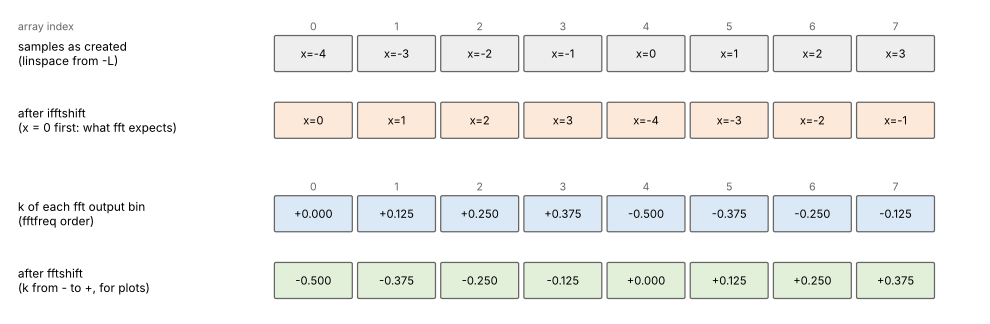

* **`ifftshift`** (before the FFT) moves the sample at $x = 0$ to index 0; the negative-$x$ samples go to the end, which
  is the same thing for the FFT because it treats the signal as periodic.
* **`fftshift`** (after the FFT) moves the negative frequencies to the front, so the plot goes from $-k$ to $+k$.

**What happens without `ifftshift`.** The FFT would then treat the sample at $x = -40$ as if it were at $x = 0$, i.e. it
would see the function moved 40 units to the right. By the Time Shifting Property (A.7) this multiplies $F(k)$ by
$e^{-2\pi i k L}$ with $L = 40$, and at the FFT frequencies $k_m = m/80$ that factor is $e^{-i\pi m} = (-1)^m$: every
other value flips sign. The magnitude is unaffected, but the real part becomes a zig-zag:

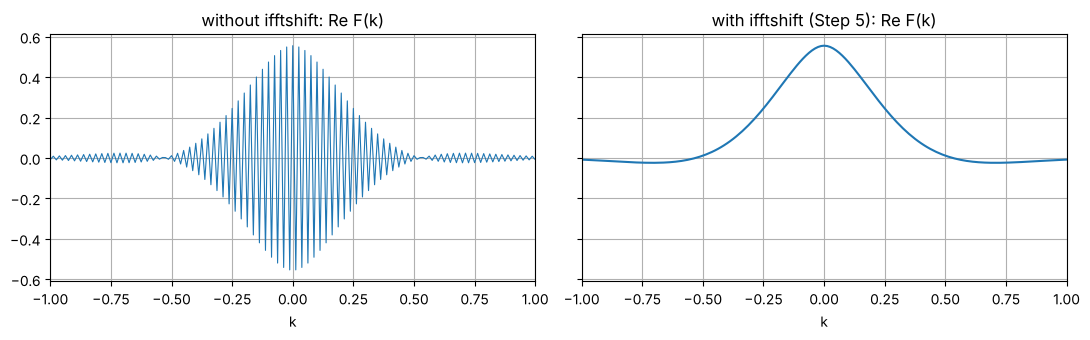

max difference of |F|: 0.0


In [11]:
F_no_shift = fftshift(fft(y1) * dx)                  # same as fourier(y1) but WITHOUT ifftshift (first sample at x = -40)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)  # two panels side by side, same vertical scale
ax[0].plot(k, np.real(F_no_shift), lw=0.8)           # real part flips sign at every other k: a zig-zag
ax[0].set_title("without ifftshift: Re F(k)")        # panel title
ax[1].plot(k, np.real(F1))                           # the correct real part from Step 5
ax[1].set_title("with ifftshift (Step 5): Re F(k)")  # panel title
for axis in ax:                                      # common settings for both panels
    axis.set_xlim(-1, 1)                             # zoom in on the interesting k range
    axis.set_xlabel("k")                             # horizontal axis label
    axis.grid(True)                                  # light grid
plt.tight_layout()                                   # avoid overlapping labels
plt.show()                                           # render the figure

print("max difference of |F|:", np.max(np.abs(np.abs(F_no_shift) - np.abs(F1))))  # magnitudes agree: only the phase was wrong

## A.5 Symmetry: why $\text{Im}\,F(k) = 0$ for an even function
$f(x) = 1/(a^2x^4 + b^2)$ is **even**: $f(-x) = f(x)$, because $(-x)^4 = x^4$. Cosine is even and sine is odd. The product
of an even and an odd function is odd. The left half of an odd function is the mirror image of the right half with the
sign flipped, so the two areas cancel and the total area is zero:

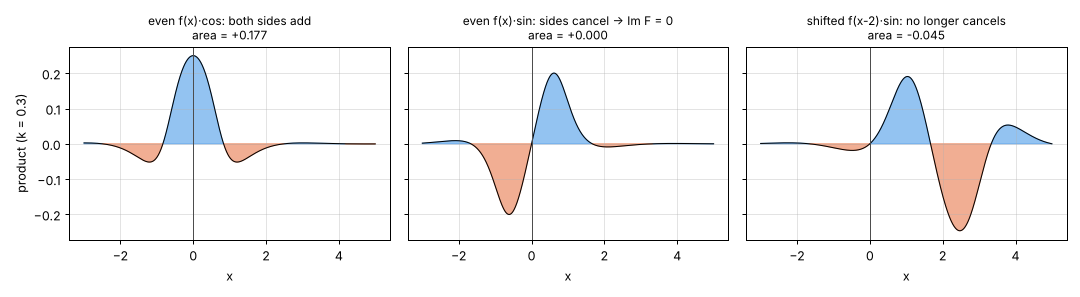

* **Left:** $f(x)\cos(2\pi k x)$ is even; both sides add up, giving the real part of $F(k)$.
* **Middle:** $f(x)\sin(2\pi k x)$ is odd; the two sides cancel exactly, so $\text{Im}\,F(k) = 0$ (versions 1 and 2).
  The 4-point example in A.4 was real for the same reason.
* **Right:** after the shift, $f(x - 2)$ is not symmetric about $x = 0$, so the two sides no longer cancel and
  $\text{Im}\,F(k) = -(\text{area}) \neq 0$ (version 3).

For any real function, $\cos(-\theta) = \cos\theta$ and $\sin(-\theta) = -\sin\theta$ also give
$\text{Re}\,F(-k) = \text{Re}\,F(k)$ (even in $k$) and $\text{Im}\,F(-k) = -\text{Im}\,F(k)$ (odd in $k$). This is the
"mirror image" of negative frequencies seen in `scipy_fft.ipynb`, and it holds for all three versions in Problem 1.

## A.6 The Similarity Theorem and the uncertainty principle
Lecture 9 (slide 18), the **Similarity Theorem** (time-scaling property): if a function becomes narrower in one domain,
it becomes broader by the same factor in the other domain. The slides call the factor $a$; to avoid confusion with the
$a$ in $f(x)$, call it $c$:

$$g(x) \to G(k) \quad\Longrightarrow\quad g(c\,x) \to \frac{1}{|c|}\,G\!\left(\frac{k}{c}\right).$$

The lecture's example (slide 17) is the rectangular pulse, whose transform is a sinc function. A rectangle of width $w$ has the
transform $w\,\dfrac{\sin(\pi w k)}{\pi w k}$, with first zeros at $k = \pm 1/w$ (slide 17 writes the shape as
$\text{sinc} = \sin(\cdot)/(\cdot)$; the $\pi$ comes from measuring $k$ in cycles per unit):

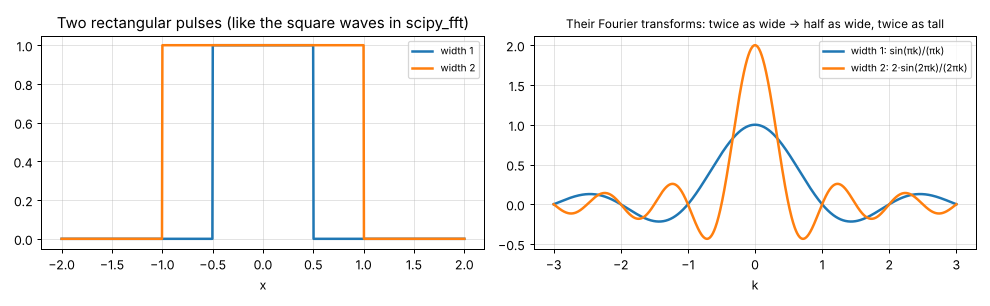

Doubling the width of the pulse halves the width of its transform (first zero at $k = 0.5$ instead of 1) and doubles its
height ($F(0)$ is the area, which doubled). This is what `scipy_fft.ipynb` showed with the narrow and wide square waves.
The reason: a wide pulse changes slowly, so only slow waves "fit" it (A.3).

**In Problem 1.** Step 6 writes $f(x) = \frac{1}{b^2}\,g(x/s)$ with $g(u) = 1/(u^4 + 1)$ and width $s = (b/a)^{1/2}$,
so $c = 1/s$ and $F(k) = \frac{s}{b^2}\,G(s\,k)$. With $b = 2$, going from $a = 2$ to $a = 1$ changes the width $s$ from
1 to $\sqrt{2}$: $f$ becomes $\sqrt{2}$ times wider, and $F(k)$ becomes $\sqrt{2}$ times narrower and taller. The solution
measured exactly this (Step 7): $F(0)$ from 0.555 to 0.785 and the first zero from 0.530 to 0.375, both ratios
$\approx 1.414$.

**The uncertainty principle** (Lecture 9, slide 19) is the general form of this rule: the spread of $f$ in $x$ times the
spread of $F$ in $k$ cannot be smaller than a fixed constant. A function cannot be narrow in both domains. In speech
analysis this is the trade-off in a spectrogram: a short window (good timing) gives coarse frequencies, and a long window
(fine frequencies) gives poor timing; the 20 ms windows used for the spectrograms in `lec09_speech_analysis.ipynb` are a
compromise.

## A.7 The Time Shifting Property
Lecture 9 (slide 18): shifting a function by $x_0$ multiplies its transform by a phase factor. With $k$ in cycles per unit
(the `scipy.fft` convention):

$$f(x - x_0) \;\to\; e^{-2\pi i k x_0}\,F(k).$$

(Slide 18 writes this factor in short form as $e^{ikx_0}$; with the definition of $F(k)$ on slide 17, the exact factor
is $e^{-2\pi i k x_0}$, as the next line shows.) **Why:** substitute $u = x - x_0$ in the integral:
$\int f(x - x_0)\,e^{-2\pi i k x}\,dx = \int f(u)\,e^{-2\pi i k (u + x_0)}\,du = e^{-2\pi i k x_0}\,F(k)$.

The factor $e^{-2\pi i k x_0}$ has magnitude 1 (it is a point on the unit circle of A.2), so it does not change $|F(k)|$;
it only **turns** $F(k)$ by the angle $360° \cdot k\,x_0$ (clockwise for $k > 0$, counter-clockwise for $k < 0$).
For $x_0 = 2$ that is $720° \cdot k$:

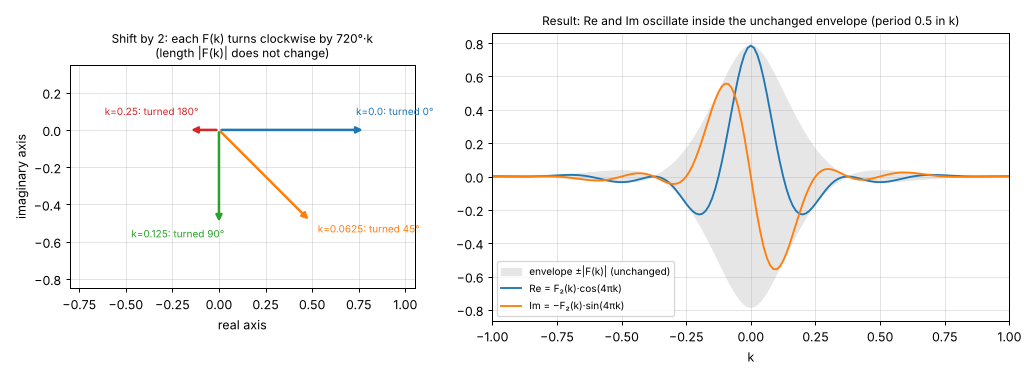

| $k$ | angle $720°\cdot k$ | factor $e^{-4\pi i k}$ | shifted $F_3(k)$ | real part | imaginary part |
|---|---|---|---|---|---|
| 0 | 0° | $1$ | $F_2(0)$ | $F_2(0) = 0.785$ | 0 |
| 0.125 | 90° | $-i$ | $-i\,F_2$ | 0 | $-F_2(0.125)$ |
| 0.25 | 180° | $-1$ | $-F_2$ | $-F_2(0.25)$ | 0 |
| 0.5 | 360° | $1$ | $F_2$ | $F_2(0.5)$ | 0 |

So, as $k$ increases, $F_3(k)$ keeps turning while its length follows $|F_2(k)|$: the real part is
$F_2(k)\cos(4\pi k)$ and the imaginary part is $-F_2(k)\sin(4\pi k)$, oscillating with period $1/x_0 = 0.5$ inside the
unchanged envelope $\pm|F_2(k)|$ (right picture). A larger shift would make them oscillate faster. The cell below checks the table with
the arrays from the solution.

**Why this matters for speech.** Spectrograms and MFCCs (Lecture 9) take the FFT of short frames of the recording and
keep only the magnitude. By the Time Shifting Property, the phase mostly records exactly where the waves sit inside the
frame, which matters little for recognizing a sound, while the magnitude records which frequencies are present.

In [12]:
for kk in [0.0, 0.125, 0.25, 0.5]:                         # the k values from the table above
    i = np.argmin(np.abs(k - kk))                          # FFT bin at this k (k is a multiple of 0.0125, so it is exact)
    factor = np.round(np.exp(-2j * np.pi * k[i] * 2), 6) + 0j  # shift factor e^{-2 pi i k x0}, x0 = 2 (+0j removes "-0")
    F3_i = np.round(F3[i], 4) + 0j                         # shifted transform at this k, rounded to 4 digits
    print(f"k = {k[i]:.3f}:  factor = {factor:.0f},  F2 = {F2[i].real:.4f},  F3 = {F3_i:.4f}")  # compare with the table

k = 0.000:  factor = 1+0j,  F2 = 0.7854,  F3 = 0.7854+0.0000j
k = 0.125:  factor = 0-1j,  F2 = 0.5064,  F3 = 0.0000-0.5064j
k = 0.250:  factor = -1+0j,  F2 = 0.1633,  F3 = -0.1633+0.0000j
k = 0.500:  factor = 1+0j,  F2 = -0.0339,  F3 = -0.0339+0.0000j


## A.8 Summary: which idea explains which result

| Result in Problem 1 | Idea | Section |
|---|---|---|
| The FFT of the samples, times $dx$, matches the exact $F(k)$ | the integral as a sum of rectangles | A.3, A.4 |
| `ifftshift` is needed; without it Re $F(k)$ zig-zags | the FFT measures positions from the first sample | A.4, A.7 |
| Im $F(k) = 0$ for versions 1 and 2 | $f$ is even, $f \cdot \sin$ is odd | A.5 |
| $F(k)$ has a peak at $k = 0$ and small negative side lobes | $F(k)$ = area of $f$ times a wave; the exact $F(k)$ is a damped oscillation | A.3, Step 6 |
| $a = 1$: $F(k)$ is $\sqrt{2}$ times narrower and taller | Similarity Theorem | A.6 |
| $x \to x-2$: same $\lvert F\rvert$, Re and Im oscillate with period 0.5 | Time Shifting Property | A.7 |